In [1]:
from pathlib import Path
import os, re, json, hashlib, platform, time, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.optimize import minimize_scalar
import openpyxl, xlrd
try:
    from IPython.display import display
except ImportError:
    def display(value): print(value.to_string(index=False) if hasattr(value,'to_string') else value)

plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
EXPLICIT_DATA_DIR = os.environ.get('HAEMOGRAPH_DATA_DIR', '')
candidates = [Path(EXPLICIT_DATA_DIR)] if EXPLICIT_DATA_DIR else []
candidates += [Path.cwd()/p for p in ('data', 'upload', '.', '../upload', '../../upload')]
DATA_DIR = next((p.resolve() for p in candidates if p.is_dir() and
                any('JUN18' in f.name.upper() for f in p.glob('*.xlsx'))), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set HAEMOGRAPH_DATA_DIR to the folder containing the supplied workbooks.')
FILES = sorted([p for p in DATA_DIR.iterdir() if p.suffix.lower() in ('.xlsx', '.xls')])
OUT = Path.cwd()/'haemograph_outputs'
OUT.mkdir(exist_ok=True)
MANIFEST = pd.DataFrame([{'file':p.name, 'bytes':p.stat().st_size,
                          'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in FILES])
print('Input folder:', DATA_DIR)
display(MANIFEST)
VERSIONS = {'python':platform.python_version()}
for package in ['numpy','scipy','pandas','matplotlib','openpyxl','xlrd']:
    VERSIONS[package] = importlib.metadata.version(package)
print('Versions:', VERSIONS)

Input folder: C:\Users\Rohan Mathew\Desktop\Data Science Unimelb\Semester Four\Capestone2


,file,bytes,sha256
0,12FEB20 UDEL Blood.xlsx,1221984,e6755723bc8a3fced9d79af424e702eac293a9dd2eb366...
1,14MAR19b SS SAOS STEP LAOS etc.xlsx,1631465,34f30219d3330fcec24664fbb26b7385aa9e14f48ca29c...
2,27FEB19 UDEL Blood.xlsx,1587275,87be863e9e038accc6f3bfd2643111507db0cf32751544...
3,JUN18.xlsx,1717560,04b4229068775267cc5f09519d423f446a77ca8e9fa0ac...
4,NOV18 UDEL ARESG2 DATA.xlsx,748224,e16df9ef5e7caa1ad9fac43a9454be5e6b0db3a875ce48...
5,TJC2_17A1.xls,1374720,131bea6a3b8107e9664e2885e07d81a18a4985fa159616...


Versions: {'python': '3.13.9', 'numpy': '2.3.5', 'scipy': '1.16.3', 'pandas': '2.3.3', 'matplotlib': '3.10.6', 'openpyxl': '3.1.5', 'xlrd': '2.0.2'}


## 2. Endpoint and physics

Distinguish biochemical activation, a detectable mechanical change, the rheological gel point and an instrument-specific clot-time threshold. They need not coincide.

For linear oscillatory response at a specified frequency,
$$\sigma(t)=\gamma_0[G'(\omega)\sin(\omega t)+G''(\omega)\cos(\omega t)].$$

In LAOS, the first-harmonic quantities $G'_1$ and $G''_1$ depend on strain amplitude; higher harmonics describe nonlinear response. A first-harmonic crossover during an amplitude sweep is not evidence of clot formation.

The Winter–Chambon critical-gel criterion involves a common power-law frequency dependence $G',G''\propto\omega^n$ and frequency-independent $\tan\delta=\tan(n\pi/2)$. Equality $G'=G''$ occurs in this relation only for $n=1/2$. Single-frequency crossover is an operational marker, not a universal gel-point definition. Multiple frequencies must probe a sufficiently short interval relative to material evolution.

Sources: Pincot et al. (2023), experimental section and Eq. 23; [TA Instruments RH157](https://www.tainstruments.com/applications-notes/evaluating-epoxy-curing-using-frequency-chirps-rh157/); [Badiei et al. (2015)](https://eprints.whiterose.ac.uk/id/eprint/108235/1/Effects%20of%20unidirectional%20flow%20shear%20stresses%20on%20the%20formation,%20fractal%20microstructure%20and%20rigidity%20of%20incipient%20whole%20blood%20clots%20and%20fibrin%20gels.pdf).

## 3. Protocol-aware ingestion and provenance

Each record retains file, sheet, column-block start, title, units and a unique identifier. Header rows are detected instead of assumed. All numeric rows are retained, including irregularly sampled protocols. Oscillatory feature extraction below is limited to ordinary LAOS with paired stress and strain; UDLAOS, ramps, steps and other protocols remain inventoried for separate analyses.

In [2]:
def number(v):
    try: return float(v)
    except (TypeError, ValueError): return np.nan

def protocol_of(sheet, title):
    text = (sheet+' '+title).lower()
    for key, name in [('udlaos','UDLAOS'),('helton','triangle ramp'),('revers','reversal'),
                      ('cessation','cessation'),('srfs','SRFS'),('laos','LAOS')]:
        if key in text: return name
    if 'step' in text: return 'step'
    return 'summary/other'

def read_xlsx(path):
    records, summaries = [], []
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    for ws in wb:
        grid = [list(row) for row in ws.iter_rows(values_only=True)]
        if len(grid)<3: continue
        width=max(map(len,grid)); grid=[r+[None]*(width-len(r)) for r in grid]
        header = next((i for i,r in enumerate(grid[:6]) if
                       any(str(v).strip().lower()=='step time' for v in r)), None)
        if header is None:
            summaries.append({'file':path.name,'sheet':ws.title,'rows':len(grid),'columns':width})
            continue
        used=[any(row[j] not in (None,'') for row in grid) for j in range(width)]
        j=0
        while j<width:
            if not used[j]: j+=1; continue
            start=j
            while j<width and used[j]: j+=1
            stop=j
            cols, units = {}, {}
            for c in range(start,stop):
                raw=str(grid[header][c] or '').strip()
                if not raw: continue
                key=raw; suffix=2
                while key in cols: key=f'{raw}_{suffix}'; suffix+=1
                cols[key]=np.array([number(r[c]) for r in grid[header+2:]],float)
                units[key]=str(grid[header+1][c] or '').strip()
            if not cols: continue
            title=' | '.join(str(v) for v in (grid[header-1][start:stop] if header else [])
                             if v not in (None,''))
            records.append({'id':f'{path.name}::{ws.title}::col{start+1}', 'file':path.name,
                            'specimen_id':path.stem, 'sheet':ws.title, 'column_start':start+1,
                            'title':title,'protocol':protocol_of(ws.title,title),
                            'columns':cols,'units':units,'material':'EDTA whole blood'})
    wb.close()
    return records,summaries

RECORDS, SUMMARY_SHEETS, POLY_SWEEPS = [], [], []
for p in FILES:
    if p.suffix.lower()=='.xlsx':
        rr,ss=read_xlsx(p); RECORDS.extend(rr); SUMMARY_SHEETS.extend(ss)

### PolySTAT units require verification

The `.xls` strain unit field is blank. In the supplied A1 summary, oscillation displacement in radians multiplied by the instrument's strain constant in 1/rad reproduces the recorded oscillation strain. This supports **dimensionless strain**, not percent. The notebook verifies that identity and uses dimensionless values; multiply by 100 only when explicitly reporting percent. Thus the README's amplitude percentages are not adopted without checking.

Raw `Sine Strain` uses the same strain convention here, supported by comparison with the summary moduli. A metadata change in future files should trigger a review of this assumption. The highest amplitude is destructive mechanical loading of a formed clot, not a temporal coagulation endpoint.

In [3]:
POLY_UNIT_CHECKS=[]
for p in FILES:
    if p.suffix.lower()!='.xls': continue
    wb=xlrd.open_workbook(str(p))
    sweep=None
    for ws in wb.sheets():
        if ws.nrows<4: continue
        labels=[str(x).strip() for x in ws.row_values(1)]
        units=[str(x).strip() for x in ws.row_values(2)]
        def arr(name):
            return np.array([number(ws.cell_value(r,labels.index(name))) for r in range(3,ws.nrows)])
        if ws.name.startswith('Amplitude sweep'):
            strain=arr('Oscillation strain')
            geometry=arr('Oscillation displacement')*arr('Strain constant')
            rel=float(np.nanmax(np.abs(strain-geometry)/np.maximum(np.abs(strain),1e-12)))
            POLY_UNIT_CHECKS.append({'file':p.name,'geometry_identity_max_relative_error':rel,
                                    'strain_unit_used':'dimensionless'})
            if rel>0.01: raise ValueError(f'Review strain units in {p.name}; geometry identity failed')
            sweep=pd.DataFrame({'file':p.name,'step':np.arange(len(strain))+1,
                                'strain_fraction':strain,'Gp_Pa':arr('Storage modulus'),
                                'Gpp_Pa':arr('Loss modulus'),'tan_delta':arr('Tan(delta)'),
                                'omega_rad_s':arr('Angular frequency')})
            POLY_SWEEPS.append(sweep)
    if sweep is None: raise ValueError(f'Missing amplitude sweep in {p.name}')
    for ws in wb.sheets():
        if not ws.name.startswith('Sine Strain'): continue
        labels=[str(x).strip() for x in ws.row_values(1)]
        units=[str(x).strip() for x in ws.row_values(2)]
        cols={name:np.array([number(ws.cell_value(r,c)) for r in range(3,ws.nrows)])
              for c,name in enumerate(labels) if name}
        index=int(ws.name.rsplit('-',1)[1].strip())-2
        omega=float(sweep.iloc[index]['omega_rad_s'])
        RECORDS.append({'id':f'{p.name}::{ws.name}', 'file':p.name,'specimen_id':p.stem,
                        'sheet':ws.name,'column_start':1,'title':f'omega={omega}',
                        'protocol':'LAOS','columns':cols,'units':dict(zip(labels,units)),
                        'material':'formed fibrin clot','summary_step':index+1})
print('PolySTAT strain convention check:')
display(pd.DataFrame(POLY_UNIT_CHECKS))
SWEEPS=pd.concat(POLY_SWEEPS,ignore_index=True) if POLY_SWEEPS else pd.DataFrame()
display(SWEEPS.round(6))

PolySTAT strain convention check:


,file,geometry_identity_max_relative_error,strain_unit_used
0,TJC2_17A1.xls,0.000003,dimensionless


,file,step,strain_fraction,Gp_Pa,Gpp_Pa,tan_delta,omega_rad_s
0,TJC2_17A1.xls,1,0.009895,0.293204,0.075134,0.256253,0.628319
1,TJC2_17A1.xls,2,0.099651,0.321920,0.067772,0.210524,0.628319
2,TJC2_17A1.xls,3,0.880634,1.490790,0.238357,0.159886,0.628319
3,TJC2_17A1.xls,4,11.297500,0.366612,0.106613,0.290806,0.628319
4,TJC2_17A1.xls,5,104.358000,0.004502,0.020954,4.654820,0.628319


In [4]:
def find_column(rec, name):
    return next((k for k in rec['columns'] if k.strip().lower()==name.lower()), None)

def aligned_channels(rec):
    keys=[find_column(rec,k) for k in ['Step time','Stress','Strain']]
    if any(k is None for k in keys): return None,'missing paired time/stress/strain'
    t,s,g=[rec['columns'][k] for k in keys]
    ok=np.isfinite(t)&np.isfinite(s)&np.isfinite(g)
    dropped=int((~ok).sum()); t,s,g=t[ok],s[ok],g[ok]
    if len(t)<32: return None,'fewer than 32 paired samples'
    if np.any(np.diff(t)<0): return None,'time reset: segment explicitly before analysis'
    keep=np.r_[True,np.diff(t)>0]; duplicates=int((~keep).sum())
    t,s,g=t[keep],s[keep],g[keep]
    su=rec['units'][keys[1]].lower()
    if su=='mpa': s=s*1e6
    elif su!='pa': return None,f'unsupported stress unit {su}'
    gu=rec['units'][keys[2]].strip()
    if gu=='%': g=g/100
    elif gu in ('(-)','-','') and (gu or rec['material']=='formed fibrin clot'): pass
    else: return None,f'unverified strain unit {gu!r}'
    dt=np.diff(t); fs=1/np.median(dt)
    return dict(t=t,stress=s,strain=g,fs=fs,dropped=dropped,duplicates=duplicates,
                max_gap_ratio=float(dt.max()/np.median(dt))), 'ok'

inv=[]
for rec in RECORDS:
    a,why=aligned_channels(rec)
    inv.append({k:rec[k] for k in ['id','file','specimen_id','sheet','title','protocol','material']}|
               {'paired_usable':a is not None,'status':why,'n':len(a['t']) if a else 0,
                'fs_Hz':a['fs'] if a else np.nan,'max_gap_ratio':a['max_gap_ratio'] if a else np.nan})
INVENTORY=pd.DataFrame(inv)
print('Protocol inventory (records, not independent participants):')
display(INVENTORY.groupby(['material','protocol']).agg(records=('id','size'),
        paired_usable=('paired_usable','sum')).reset_index())
display(pd.DataFrame(SUMMARY_SHEETS))
assert INVENTORY.id.is_unique, 'Record identifiers must remain unique.'
print('No common 33 Hz rate is imposed. Recorded timestamps and actual sample rates are retained.')

Protocol inventory (records, not independent participants):


,material,protocol,records,paired_usable
0,EDTA whole blood,LAOS,81,80
1,EDTA whole blood,SRFS,6,6
2,EDTA whole blood,UDLAOS,57,40
3,EDTA whole blood,cessation,10,0
4,EDTA whole blood,reversal,9,0
5,EDTA whole blood,step,51,51
6,EDTA whole blood,triangle ramp,69,63
7,formed fibrin clot,LAOS,5,5


,file,sheet,rows,columns
0,12FEB20 UDEL Blood.xlsx,SS and SAOS,53,17
1,14MAR19b SS SAOS STEP LAOS etc.xlsx,SS & SAOS,28,17
2,27FEB19 UDEL Blood.xlsx,SS and SAOS,28,17
3,JUN18.xlsx,Steady State & SAOS,29,19
4,NOV18 UDEL ARESG2 DATA.xlsx,SS & SAOS,32,11


No common 33 Hz rate is imposed. Recorded timestamps and actual sample rates are retained.


## 4. Oscillatory feature extraction

Fit sine/cosine terms at the imposed angular frequency and its first five harmonics to both measured stress and strain, with intercept and linear drift terms. Their complex fundamental ratio gives $G'_1+iG''_1$. Report stress $I_3/I_1$ and $I_5/I_1$ separately from strain harmonic contamination, fit residual and cycle count.

The title or summary supplies the drive frequency; the highest stress-spectrum peak is not assumed to be the fundamental. Negative modulus estimates are retained and flagged, not made positive. Residuals are quality indicators, not an automatic “noise” label; unmodelled physical behaviour may contribute. No universal 6 dB gate is imposed.

For short or amplitude-dependent recordings, these are descriptive first-harmonic features. They are not a gel-point detector. Every rejection and quality flag is retained in the exported tables.

In [5]:
def omega_of(rec):
    match=re.search(r'omega\s*=\s*([\d.]+)',rec['title'],re.I)
    return float(match.group(1)) if match else None

def harmonic_fit(t,y,omega,max_harmonic=5):
    tc=t-np.mean(t)
    X=[np.ones(len(t)),tc/max(np.ptp(t),1e-12)]
    for h in range(1,max_harmonic+1): X.extend([np.sin(h*omega*t),np.cos(h*omega*t)])
    X=np.column_stack(X)
    beta,_,rank,_=np.linalg.lstsq(X,y,rcond=None)
    if rank<X.shape[1]: raise ValueError('rank-deficient harmonic fit')
    ph=np.array([beta[3+2*h]-1j*beta[2+2*h] for h in range(max_harmonic)])
    pred=X@beta
    return ph,float(np.sqrt(np.mean((y-pred)**2))),pred

FEATURE_ROWS, REJECTIONS, SEEN_WAVEFORMS = [], [], {}
for rec in RECORDS:
    if rec['protocol']!='LAOS': continue
    a,why=aligned_channels(rec); omega=omega_of(rec)
    if a is None or not omega:
        REJECTIONS.append({'id':rec['id'],'reason':why if a is None else 'missing imposed frequency'}); continue
    t,s,g=a['t'],a['stress'],a['strain']; cycles=np.ptp(t)*omega/(2*np.pi)
    if cycles<0.9:
        REJECTIONS.append({'id':rec['id'],'reason':'less than 0.9 measured cycle'}); continue
    if 5*omega/(2*np.pi)>=0.4*a['fs']:
        REJECTIONS.append({'id':rec['id'],'reason':'fifth harmonic too close to Nyquist'}); continue
    ps,rs,_=harmonic_fit(t,s,omega); pg,rg,_=harmonic_fit(t,g,omega)
    if abs(pg[0])<1e-10:
        REJECTIONS.append({'id':rec['id'],'reason':'unresolved strain fundamental'}); continue
    G=ps[0]/pg[0]
    flags=[]
    nominal_match=re.search(r'Gamma\s*=\s*([\d.]+)',rec['title'],re.I)
    nominal=float(nominal_match.group(1)) if nominal_match else np.nan
    if np.isfinite(nominal) and abs(abs(pg[0])-nominal)/max(nominal,1e-12)>.05:
        flags.append('measured strain differs from nominal by >5%')
    fingerprint=hashlib.sha256(np.column_stack([t,s,g]).tobytes()).hexdigest()
    duplicate_of=SEEN_WAVEFORMS.get(fingerprint,'')
    if duplicate_of: flags.append('exact duplicate paired waveform')
    else: SEEN_WAVEFORMS[fingerprint]=rec['id']
    if cycles<3: flags.append('short record: fewer than 3 cycles')
    if rs/max(abs(ps[0]),1e-12)>.2: flags.append('large stress residual')
    if abs(pg[2])/abs(pg[0])>.05: flags.append('strain third harmonic >5%')
    if G.real<0 or G.imag<0: flags.append('negative modulus estimate')
    FEATURE_ROWS.append({k:rec[k] for k in ['id','file','specimen_id','sheet','title','material']}|
        {'omega_rad_s':omega,'cycles':cycles,'fs_Hz':a['fs'],'strain_fraction':abs(pg[0]),
         'Gp1_Pa':G.real,'Gpp1_Pa':G.imag,'phase_deg':np.degrees(np.angle(G)),
         'stress_I3_I1':abs(ps[2])/max(abs(ps[0]),1e-12),
         'stress_I5_I1':abs(ps[4])/max(abs(ps[0]),1e-12),
         'strain_I3_I1':abs(pg[2])/abs(pg[0]),
         'stress_residual_over_I1':rs/max(abs(ps[0]),1e-12),
         'nominal_strain_fraction':nominal,'duplicate_of':duplicate_of,
         'quality_flags':'; '.join(flags) or 'none', 'summary_step':rec.get('summary_step',np.nan)})
FEATURES=pd.DataFrame(FEATURE_ROWS)
print('LAOS records fitted:',len(FEATURES),'| rejected:',len(REJECTIONS))
display(FEATURES.groupby('material').agg(records=('id','size'),files=('file','nunique'),
    median_cycles=('cycles','median'),median_I3_I1=('stress_I3_I1','median')).round(4))
display(FEATURES[['file','sheet','omega_rad_s','strain_fraction','Gp1_Pa','Gpp1_Pa',
                  'stress_I3_I1','quality_flags']].head(10).round(5))
display(pd.DataFrame(REJECTIONS))

LAOS records fitted: 84 | rejected: 2


,records,files,median_cycles,median_I3_I1
material,,,,
EDTA whole blood,79,5,6.3622,0.0509
formed fibrin clot,5,1,0.9978,0.1807


,file,sheet,omega_rad_s,strain_fraction,Gp1_Pa,Gpp1_Pa,stress_I3_I1,quality_flags
0,12FEB20 UDEL Blood.xlsx,LAOS,1.0,0.50008,0.01458,0.02054,0.01957,large stress residual
1,12FEB20 UDEL Blood.xlsx,LAOS,1.0,1.00019,0.01003,0.01763,0.03571,large stress residual
2,12FEB20 UDEL Blood.xlsx,LAOS,1.0,5.00100,0.00232,0.01082,0.07738,none
3,12FEB20 UDEL Blood.xlsx,LAOS,1.0,10.00201,0.00108,0.00881,0.07383,none
4,12FEB20 UDEL Blood.xlsx,LAOS,1.0,50.01013,0.00007,0.00546,0.07714,none
5,12FEB20 UDEL Blood.xlsx,LAOS,1.0,100.02042,0.00003,0.00474,0.05786,none
6,12FEB20 UDEL Blood.xlsx,LAOS,5.0,0.49983,0.02519,0.04830,0.01961,none
7,12FEB20 UDEL Blood.xlsx,LAOS,5.0,0.99960,0.01534,0.04055,0.03844,none
8,12FEB20 UDEL Blood.xlsx,LAOS,5.0,4.99797,0.00372,0.02910,0.05634,none
9,12FEB20 UDEL Blood.xlsx,LAOS,5.0,9.99588,0.00208,0.02588,0.05469,none


,id,reason
0,JUN18.xlsx::LAOS::col13,missing paired time/stress/strain
1,JUN18.xlsx::LAOS::col70,missing imposed frequency


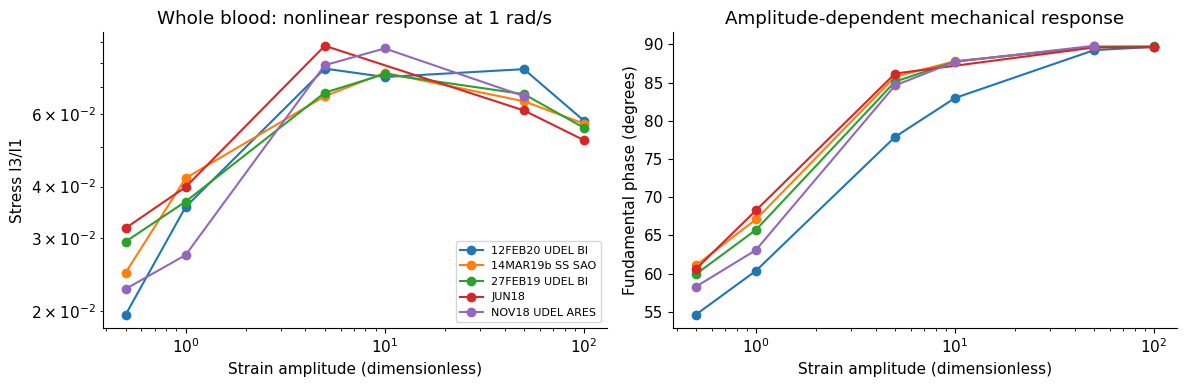

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for file,grp in FEATURES[FEATURES.material=='EDTA whole blood'].groupby('file'):
    sub=grp[np.isclose(grp.omega_rad_s,1)].sort_values('strain_fraction')
    axes[0].loglog(sub.strain_fraction,sub.stress_I3_I1,'o-',label=file.split('.')[0][:15])
    axes[1].semilogx(sub.strain_fraction,sub.phase_deg,'o-')
axes[0].set(xlabel='Strain amplitude (dimensionless)',ylabel='Stress I3/I1',title='Whole blood: nonlinear response at 1 rad/s')
axes[1].set(xlabel='Strain amplitude (dimensionless)',ylabel='Fundamental phase (degrees)',title='Amplitude-dependent mechanical response')
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()

## 5. Actual uploaded PolySTAT specimen

The original notebook's saved B1 output is not reused. The table below joins each A1 raw oscillatory sheet to its amplitude-sweep summary. It checks first-harmonic estimates against the instrument's reported values while showing discrepancies. This is a consistency check on the same measurement, not independent external validation. Differences can arise from instrument processing, the short sampled cycle, ringing, baseline handling and signal distortion.

The raw segments span approximately one cycle at 0.1 Hz. That limits inference about repeatability and low-frequency time localisation. A complete amplitude sweep contains several loading conditions from one specimen, not several independent clotting events.

,file,step,strain_fraction_summary,Gp_Pa,Gp1_Pa,Gpp_Pa,Gpp1_Pa,tan_delta,stress_I3_I1,cycles
0,TJC2_17A1.xls,1,0.00990,0.29320,0.19943,0.07513,0.07283,0.25625,0.18068,0.99779
1,TJC2_17A1.xls,2,0.09965,0.32192,0.32662,0.06777,0.06712,0.21052,0.01249,0.99779
2,TJC2_17A1.xls,3,0.88063,1.49079,1.49690,0.23836,0.23681,0.15989,0.16583,0.99779
3,TJC2_17A1.xls,4,11.29750,0.36661,0.35590,0.10661,0.11294,0.29081,0.31562,0.99778
4,TJC2_17A1.xls,5,104.35800,0.00450,0.00491,0.02095,0.02084,4.65482,0.27956,0.99779


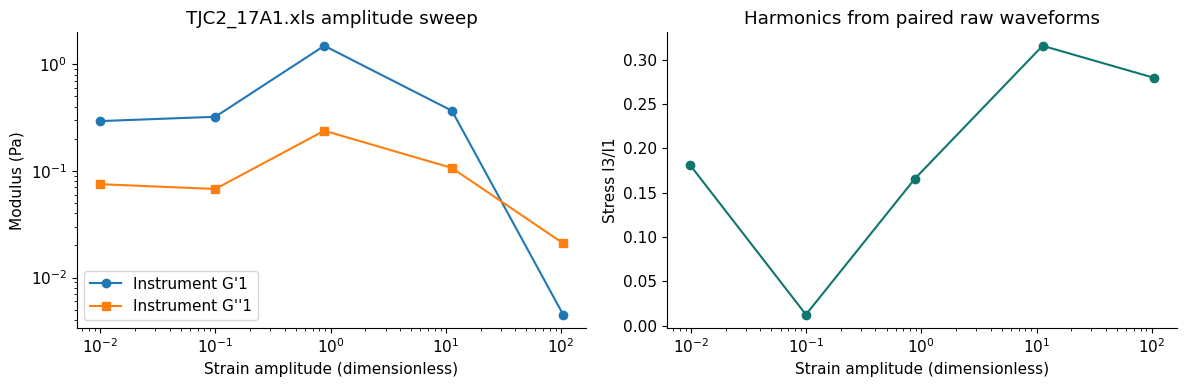

In [7]:
POLY_FEATURES=FEATURES[FEATURES.material=='formed fibrin clot'].copy()
POLY_COMPARE=POLY_FEATURES.merge(SWEEPS,left_on=['file','summary_step'],right_on=['file','step'],suffixes=('_fit','_summary'))
POLY_COMPARE['Gp_relative_difference']=(POLY_COMPARE.Gp1_Pa-POLY_COMPARE.Gp_Pa)/POLY_COMPARE.Gp_Pa
POLY_COMPARE['Gpp_relative_difference']=(POLY_COMPARE.Gpp1_Pa-POLY_COMPARE.Gpp_Pa)/POLY_COMPARE.Gpp_Pa
display(POLY_COMPARE[['file','step','strain_fraction_summary','Gp_Pa','Gp1_Pa','Gpp_Pa','Gpp1_Pa',
                      'tan_delta','stress_I3_I1','cycles']].round(5))
if len(POLY_COMPARE):
    d=POLY_COMPARE[POLY_COMPARE.file==POLY_COMPARE.file.iloc[0]].sort_values('step')
    fig,axes=plt.subplots(1,2,figsize=(12,4))
    axes[0].loglog(d.strain_fraction_summary,d.Gp_Pa,'o-',label="Instrument G'1")
    axes[0].loglog(d.strain_fraction_summary,d.Gpp_Pa,'s-',label="Instrument G''1")
    axes[0].set(xlabel='Strain amplitude (dimensionless)',ylabel='Modulus (Pa)',title=d.file.iloc[0]+' amplitude sweep')
    axes[0].legend()
    axes[1].semilogx(d.strain_fraction_summary,d.stress_I3_I1,'o-',color='#0F766E')
    axes[1].set(xlabel='Strain amplitude (dimensionless)',ylabel='Stress I3/I1',title='Harmonics from paired raw waveforms')
    fig.tight_layout();plt.show()

## 6. Fair local-estimator benchmark

Three explicitly named estimators share the same six-second trailing window, paired channels, known 0.5 Hz excitation and 0.5-second update step:

1. **Harmonic least squares:** simultaneous fundamental and harmonic fit.
2. **Hann Fourier:** tapered complex demodulation at the imposed frequency; a local Fourier/STFT coefficient.
3. **Gaussian Morlet coefficient ratio:** direct complex Gaussian-kernel analysis at the imposed frequency, with a zero-mean kernel and paired-channel ratio. This is a documented single-scale wavelet feature estimator, not a CWT ridge detector or a Paul/Morse implementation.

The Gaussian kernel has standard deviation one sixth of the window and support ±3 standard deviations. The same mathematical implementation is used for both channels. Window endpoints are the times when an estimate becomes available; window midpoints are used only to assess feature-recovery error. No future data enter the detector.

DWT/SWT, multi-frequency CWT maps and alternative wavelets are not ranked here. They can be added when they produce the same observable and respect the same latency budget. No ordinal family priors or weighted “winner” table are used.

In [8]:
METHODS=['Harmonic LS','Hann Fourier','Morlet ratio']
WINDOW_S=6.0; UPDATE_S=0.5; BASELINE_END_S=20.0
PERSISTENCE=3; Z_THRESHOLD=5.0; RELATIVE_NOISE_FLOOR=0.05

def local_modulus(t,s,g,omega,method):
    if method=='Harmonic LS':
        ps,_,_=harmonic_fit(t,s,omega,3); pg,_,_=harmonic_fit(t,g,omega,3)
        return ps[0]/pg[0] if abs(pg[0])>1e-10 else complex(np.nan,np.nan)
    tc=t-np.mean(t)
    if method=='Hann Fourier': w=np.hanning(len(t))
    elif method=='Morlet ratio': w=np.exp(-0.5*(tc/(WINDOW_S/6))**2)
    else: raise ValueError(method)
    carrier=np.exp(-1j*omega*tc)
    kernel=w*(carrier-np.sum(w*carrier)/np.sum(w))
    den=np.sum(kernel*g)
    return np.sum(kernel*s)/den if abs(den)>1e-10 else complex(np.nan,np.nan)

def window_features(t,s,g,omega,method):
    out=[]
    for end in np.arange(t[0]+WINDOW_S,t[-1]+1e-9,UPDATE_S):
        mask=(t>end-WINDOW_S)&(t<=end)
        G=local_modulus(t[mask],s[mask],g[mask],omega,method)
        out.append({'time_end_s':end,'time_mid_s':end-WINDOW_S/2,'Gp':G.real,'Gpp':G.imag})
    return pd.DataFrame(out)

def detect_persistent_rise(df):
    baseline=df.loc[df.time_end_s<=BASELINE_END_S,'Gp'].dropna()
    if len(baseline)<8: return np.nan
    centre=float(np.median(baseline))
    noise=max(1.4826*float(np.median(np.abs(baseline-centre))),RELATIVE_NOISE_FLOOR*abs(centre),1e-9)
    run=0
    for row in df.itertuples():
        if row.time_end_s<=BASELINE_END_S: continue
        run=run+1 if np.isfinite(row.Gp) and (row.Gp-centre)>Z_THRESHOLD*noise else 0
        if run>=PERSISTENCE: return float(row.time_end_s)
    return np.nan

print('Shared detector settings:',dict(window_s=WINDOW_S,update_s=UPDATE_S,
      persistence=PERSISTENCE,z=Z_THRESHOLD,relative_floor=RELATIVE_NOISE_FLOOR))

Shared detector settings: {'window_s': 6.0, 'update_s': 0.5, 'persistence': 3, 'z': 5.0, 'relative_floor': 0.05}


### Synthetic model and fixed evaluation cases

The strain excitation stays fixed. Stress is generated as
$$\sigma(t)=G_p(t)\gamma(t)+[G_v(t)/\omega]\dot{\gamma}(t)+a_3\sin(3\omega t)+\epsilon(t).$$

This is an illustrative time-varying parallel elastic/viscous model with known parameters, not the t-ESSTV model or a validated biochemical coagulation model. Positive cases begin a smooth elastic rise at a known injected time; negatives remain mechanically stationary. The injected rise onset is the event target and is not called a gel point. Harmonics, noise and amplitude changes are included as declared nuisance conditions.

The parameters below are fixed before evaluation. Results compare only these cases; no clinical accuracy or universal method superiority follows. The event detector is intentionally simple and is expected to miss changes that do not produce a persistent elastic rise.

In [9]:
def synthetic_case(seed,positive=True,noise=0.03,nuisance='none'):
    rng=np.random.default_rng(seed); fs=50.; omega=np.pi
    t=np.arange(0,90,1/fs); onset=40.+rng.uniform(-4,4)
    u=np.clip((t-onset)/15.,0,1); rise=u*u*(3-2*u) if positive else np.zeros_like(t)
    gp=0.6+2.4*rise; gpp=np.full_like(t,0.9)
    amp=np.full_like(t,0.5)
    if nuisance=='drive amplitude': amp[t>=45.]=0.8
    gamma=amp*np.sin(omega*t)
    # Derivative within each constant-amplitude excitation regime; the drive switch is an artifact challenge.
    gamma_dot=amp*omega*np.cos(omega*t)
    harmonic=(0.12 if nuisance=='third harmonic' else 0.03)*amp*np.sin(3*omega*t)
    stress=gp*gamma+(gpp/omega)*gamma_dot+harmonic+noise*rng.normal(size=len(t))
    strain=gamma+0.002*rng.normal(size=len(t))
    return dict(t=t,stress=stress,strain=strain,omega=omega,gp=gp,gpp=gpp,
                onset=onset if positive else np.nan,positive=positive,noise=noise,nuisance=nuisance)

BENCH_ROWS=[]; EXAMPLE={}
for positive in [False,True]:
    for noise in [0.02,0.08,0.20]:
        for idx,nuisance in enumerate(['none','third harmonic','drive amplitude']):
            case=synthetic_case(100+idx+int(noise*1000),positive,noise,nuisance)
            for method in METHODS:
                start=time.perf_counter()
                windows=window_features(case['t'],case['stress'],case['strain'],case['omega'],method)
                elapsed=time.perf_counter()-start; event=detect_persistent_rise(windows)
                truth=np.interp(windows.time_mid_s,case['t'],case['gp'])
                rmse=float(np.sqrt(np.mean((windows.Gp-truth)**2)))
                false_alarm=bool(np.isfinite(event) and (not positive or event<case['onset']))
                detected=bool(positive and np.isfinite(event) and event>=case['onset'])
                BENCH_ROWS.append(dict(method=method,positive=positive,noise=noise,nuisance=nuisance,
                    onset=case['onset'],estimate=event,false_alarm=false_alarm,detected=detected,
                    delay_s=event-case['onset'] if detected else np.nan,
                    Gp_rmse_Pa=rmse,ms_per_window=1000*elapsed/len(windows)))
                if positive and noise==0.08 and nuisance=='none': EXAMPLE[method]=(case,windows,event)
BENCH=pd.DataFrame(BENCH_ROWS)
BENCH_SUMMARY=BENCH.groupby('method').apply(lambda g:pd.Series({
    'positive_cases':int(g.positive.sum()),'detected_after_onset':int(g.detected.sum()),
    'negative_cases':int((~g.positive).sum()),'negative_false_alarms':int(g.loc[~g.positive,'false_alarm'].sum()),
    'early_false_alarms':int(g.loc[g.positive,'false_alarm'].sum()),
    'median_delay_s':g.delay_s.median(),'mean_Gp_rmse_Pa':g.Gp_rmse_Pa.mean(),
    'median_ms_per_window':g.ms_per_window.median()}),include_groups=False).reset_index()
display(BENCH_SUMMARY.round(4))
print('Runtime measurements describe this host only. Timing error excludes misses, so read it with event counts.')

,method,positive_cases,detected_after_onset,negative_cases,negative_false_alarms,early_false_alarms,median_delay_s,mean_Gp_rmse_Pa,median_ms_per_window
0,Hann Fourier,9.0,9.0,9.0,0.0,0.0,6.3915,0.0227,0.1067
1,Harmonic LS,9.0,9.0,9.0,0.0,0.0,5.9375,0.0227,0.4055
2,Morlet ratio,9.0,9.0,9.0,0.0,0.0,6.4375,0.0235,0.0967


Runtime measurements describe this host only. Timing error excludes misses, so read it with event counts.


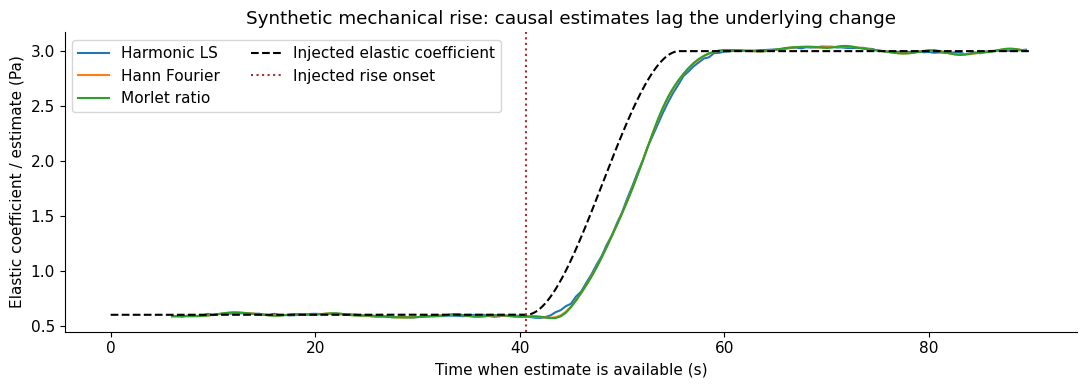

In [10]:
fig,ax=plt.subplots(figsize=(11,4))
for method,(case,windows,event) in EXAMPLE.items():
    ax.plot(windows.time_end_s,windows.Gp,label=method)
case=next(iter(EXAMPLE.values()))[0]
ax.plot(case['t'],case['gp'],'k--',label='Injected elastic coefficient')
ax.axvline(case['onset'],color='#A23030',ls=':',label='Injected rise onset')
ax.set(xlabel='Time when estimate is available (s)',ylabel='Elastic coefficient / estimate (Pa)',
       title='Synthetic mechanical rise: causal estimates lag the underlying change')
ax.legend(ncol=2);fig.tight_layout();plt.show()

## 7. Meaningful checks and limits

These checks test signal recovery, time causality and a no-event outcome. They do not require a favourite method to win. A passing check does not validate physiology. The old “a CWT method ranks first” and “at least one gel point found” checks are deliberately absent.

In [11]:
CHECKS=[]
tt=np.arange(0,60,0.02); ww=np.pi
gg=.5*np.sin(ww*tt); ss=.5*(1.2*np.sin(ww*tt)+.7*np.cos(ww*tt))
for method in METHODS:
    d=window_features(tt,ss,gg,ww,method)
    err=max(abs(d.Gp.median()-1.2),abs(d.Gpp.median()-.7))
    CHECKS.append({'check':method+' recovers stationary paired response','pass':bool(err<0.02),'value':err})
    CHECKS.append({'check':method+' allows no event','pass':bool(np.isnan(detect_persistent_rise(d))),'value':None})
    before=window_features(tt[tt<=35],ss[tt<=35],gg[tt<=35],ww,method)
    after=ss.copy();after[tt>35]+=100
    modified=window_features(tt,after,gg,ww,method)
    joined=before.merge(modified,on='time_end_s',suffixes=('_before','_after'))
    diff=float(np.max(np.abs(joined.Gp_before-joined.Gp_after)))
    CHECKS.append({'check':method+' uses no future stress','pass':bool(diff<1e-10),'value':diff})
CHECKS.append({'check':'unique raw record IDs','pass':bool(INVENTORY.id.is_unique),'value':len(INVENTORY)})
display(pd.DataFrame(CHECKS))
assert all(c['pass'] for c in CHECKS)

,check,pass,value
0,Harmonic LS recovers stationary paired response,True,2.220446e-16
1,Harmonic LS allows no event,True,NaN
2,Harmonic LS uses no future stress,True,0.000000e+00
3,Hann Fourier recovers stationary paired response,True,1.279387e-08
4,Hann Fourier allows no event,True,NaN
5,Hann Fourier uses no future stress,True,0.000000e+00
6,Morlet ratio recovers stationary paired response,True,5.905314e-07
7,Morlet ratio allows no event,True,NaN
8,Morlet ratio uses no future stress,True,0.000000e+00
9,unique raw record IDs,True,2.880000e+02


### Low-frequency wavelet coverage check

For a complex Morlet centre frequency of 1.0, the approximate analysed frequency is sampling rate / scale. The previous PolySTAT scale cap was `min(256, N//3)`. A1 has around 610 points at 61 Hz, so its lower analysed frequency was about 0.30 Hz. The 0.1 Hz drive was outside the range. A “zero-bin separation” result in that configuration is not evidence of an intrinsic CWT failure.

Expanding the scale range would include 0.1 Hz but would not create additional cycles or eliminate boundary effects. A meaningful low-frequency CWT study needs longer records and an explicit boundary/support mask. Fourier harmonic fitting also has finite-record and ringing limitations.

In [12]:
COVERAGE=[]
for rec in RECORDS:
    if rec['material']!='formed fibrin clot': continue
    a,_=aligned_channels(rec);f=omega_of(rec)/(2*np.pi);n=len(a['t'])
    low=a['fs']/min(256,n//3)
    COVERAGE.append({'file':rec['file'],'sheet':rec['sheet'],'n':n,'fs_Hz':a['fs'],
                     'duration_s':np.ptp(a['t']),'drive_Hz':f,'old_CWT_min_Hz':low,
                     'drive_inside_old_range':bool(f>=low)})
display(pd.DataFrame(COVERAGE).round(4))

,file,sheet,n,fs_Hz,duration_s,drive_Hz,old_CWT_min_Hz,drive_inside_old_range
0,TJC2_17A1.xls,Sine Strain - 2,610,60.9756,9.9779,0.1,0.3004,False
1,TJC2_17A1.xls,Sine Strain - 3,610,60.9756,9.9779,0.1,0.3004,False
2,TJC2_17A1.xls,Sine Strain - 4,610,60.9756,9.9779,0.1,0.3004,False
3,TJC2_17A1.xls,Sine Strain - 5,610,60.9756,9.9778,0.1,0.3004,False
4,TJC2_17A1.xls,Sine Strain - 6,610,60.9756,9.9779,0.1,0.3004,False


## 8. Machine learning: executable workflow, inactive without labels

Do not classify the EDTA workbooks as “liquid” and PolySTAT as “gel.” That model could learn material or instrument identity. Do not use signal-generated crossover times as clinical ground truth. More rows or overlapping windows do not increase the number of independent specimens.

For future recordings, prepare two CSVs in `DATA_DIR`:

**`coagulation_windows.csv`**: `specimen_id`, `time_end_s`, `Gp`, `Gpp`, `phase_deg`, `I3_I1`. Each feature must use a causal window from a common clock relative to activation. Use an experimentally appropriate non-destructive excitation. Unit conventions and feature validity must be recorded upstream.

**`coagulation_labels.csv`**: `specimen_id`, `group_id`, `event_observed`, `reference_event_time_s`, `observation_end_s`, `label_source`. Use donor ID for `group_id` when specimens share a donor; otherwise a verified independent specimen/batch grouping. For no event within observation, use `event_observed=0` and blank event time. `label_source` identifies an independently reviewed reference assay/gel-point assessment, not this notebook's predictions. Endpoints should include reference-time uncertainty in the eventual study report.

The function below performs outer grouped validation of an imputation + scaling + regularised logistic-regression baseline. It weights each training specimen equally, reports pooled out-of-fold AUROC and evaluates sustained event alarms per specimen. Whole donors/groups are held out together. Fixed hyperparameters and probability threshold are declared, not tuned on held-out data. Any tuning must occur inside an additional inner grouped validation loop. Five groups is a software minimum for this pilot, not a statistical sufficiency claim.

The target is “has the reference event occurred by this window end?” This estimates a current state; it does not predict an event before it happens. A future time-to-event model requires an explicit forecasting horizon and censoring-aware validation.

In [13]:
def run_grouped_ml(windows, labels):
    from sklearn.model_selection import GroupKFold
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import roc_auc_score, average_precision_score
    features=['Gp','Gpp','phase_deg','I3_I1']
    required=['specimen_id','group_id','event_observed','reference_event_time_s','observation_end_s','label_source']
    if not set(required)<=set(labels): raise ValueError('Missing reference-label columns')
    if labels.specimen_id.duplicated().any(): raise ValueError('One label row per specimen required')
    if labels.group_id.isna().any() or labels.label_source.isna().any(): raise ValueError('Grouping and provenance required')
    if not labels.event_observed.isin([0,1]).all(): raise ValueError('event_observed must be 0 or 1')
    pos=labels.event_observed.eq(1)
    if labels.loc[pos,'reference_event_time_s'].isna().any(): raise ValueError('Observed events need reference times')
    if (labels.loc[pos,'reference_event_time_s']>labels.loc[pos,'observation_end_s']).any(): raise ValueError('Event after observation end')
    if labels.observation_end_s.isna().any(): raise ValueError('Observation end times required')
    if not set(windows.specimen_id)<=set(labels.specimen_id): raise ValueError('Every window specimen needs a label')
    data=windows.merge(labels,on='specimen_id',validate='many_to_one').sort_values(['specimen_id','time_end_s'])
    if data[['specimen_id','time_end_s']].duplicated().any(): raise ValueError('Duplicate window times')
    data=data[(data.time_end_s>=0)&(data.time_end_s<=data.observation_end_s)].copy().reset_index(drop=True)
    X=data[features].replace([np.inf,-np.inf],np.nan)
    y=(data.event_observed.eq(1)&(data.time_end_s>=data.reference_event_time_s)).astype(int)
    if data.group_id.nunique()<5: raise ValueError('At least five independent groups required for this pilot')
    if y.nunique()!=2: raise ValueError('Need both pre-event/no-event and post-event windows')
    probabilities=np.full(len(data),np.nan); fold_info=[]
    for fold,(train,test) in enumerate(GroupKFold(n_splits=5).split(X,y,data.group_id),1):
        if y.iloc[train].nunique()!=2: raise ValueError('A training fold lacks one class; revise study coverage')
        if set(data.group_id.iloc[train])&set(data.group_id.iloc[test]): raise AssertionError('Group leakage')
        if X.iloc[train].isna().all().any(): raise ValueError('Feature entirely missing in a training fold')
        model=make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),
                            LogisticRegression(C=1.0,class_weight='balanced',max_iter=2000,random_state=7))
        counts=data.iloc[train].groupby('specimen_id').specimen_id.transform('size').to_numpy()
        weights=1/counts;weights=weights/weights.mean()
        model.fit(X.iloc[train],y.iloc[train],logisticregression__sample_weight=weights)
        probabilities[test]=model.predict_proba(X.iloc[test])[:,1]
        fold_info.append({'fold':fold,'train_groups':data.group_id.iloc[train].nunique(),
                          'held_out_groups':data.group_id.iloc[test].nunique()})
    data['oof_probability']=probabilities
    alarms=[]
    for specimen,d in data.groupby('specimen_id'):
        # Reset persistence across missing/irregular windows; never bridge a large gap.
        step=float(np.median(np.diff(d.time_end_s))) if len(d)>1 else np.nan
        run=0;alarm=np.nan;last=None
        for row in d.itertuples():
            if last is not None and row.time_end_s-last>1.5*step:run=0
            run=run+1 if row.oof_probability>=0.5 else 0
            last=row.time_end_s
            if run>=3:alarm=row.time_end_s;break
        ref=d.iloc[0];observed=bool(ref.event_observed)
        false=bool(np.isfinite(alarm) and (not observed or alarm<ref.reference_event_time_s))
        hit=bool(observed and np.isfinite(alarm) and alarm>=ref.reference_event_time_s)
        alarms.append({'specimen_id':specimen,'observed':observed,'alarm_s':alarm,
                       'false_alarm':false,'detected_after_reference':hit,
                       'delay_s':alarm-ref.reference_event_time_s if hit else np.nan})
    return {'window_AUROC':roc_auc_score(y,probabilities),
            'window_average_precision':average_precision_score(y,probabilities),
            'folds':pd.DataFrame(fold_info),'alarms':pd.DataFrame(alarms),'predictions':data}

wf,lf=DATA_DIR/'coagulation_windows.csv',DATA_DIR/'coagulation_labels.csv'
ML_STATUS='Not trained: no independently labelled coagulation time series supplied.'
ML_RESULT=None
if wf.exists() and lf.exists():
    ML_RESULT=run_grouped_ml(pd.read_csv(wf),pd.read_csv(lf))
    ML_STATUS='Pilot grouped out-of-fold model evaluated on supplied reference labels; review label provenance.'
    print(ML_STATUS)
    print({k:ML_RESULT[k] for k in ['window_AUROC','window_average_precision']})
    display(ML_RESULT['folds']);display(ML_RESULT['alarms'])
else: print(ML_STATUS)

Not trained: no independently labelled coagulation time series supplied.


## 9. What to request from Haemograph

Request paired excitation/response recordings spanning pre-activation, clot development and post-event behaviour, synchronized to a known activation clock. Obtain donor/specimen/replicate IDs, anticoagulant and activation protocol, temperature, sample geometry, sampling and instrument calibration metadata. Include no-event observation windows and define censoring. Request an independent rheological/assay reference with timing uncertainty; a TEG/ROTEM threshold is its own endpoint and must not silently be equated to a Winter–Chambon gel point.

Prefer measurements that remain within an experimentally established non-destructive response range for gelation tracking. Large-amplitude tests can themselves change the network. If only a single-frequency device channel is available, validate a declared mechanical onset proxy against a suitable independent reference instead of claiming a universal gel-point measurement.

Next experiments should compare physics-only event detection, the grouped ML baseline and a feature-augmented ML model on the same held-out donors, with event timing, false alarms, misses and end-to-end delay reported together. Calibration, threshold selection and feature selection belong inside the training folds. More complex models are justified only by improved held-out performance.

## 10. Outputs and defensible conclusions

This run produces a traceable protocol inventory, first-harmonic LAOS features, an A1 raw-versus-summary consistency check, controlled synthetic benchmark results and a future ML entry point. It does not produce verified coagulation times from EDTA ramps or pre-formed fibrin clots.

The notebook is intentionally a research benchmark. The three tested local estimators have different smoothing and fitting behaviour; no universal “best wavelet” or deployment-ready detector is claimed. A candidate can be selected for a specified error/latency budget only after a representative labelled evaluation.

In [14]:
TABLES={'input_manifest':MANIFEST,'protocol_inventory':INVENTORY,'laos_features':FEATURES,
        'polystat_summary':SWEEPS,'polystat_consistency':POLY_COMPARE,
        'synthetic_cases':BENCH,'synthetic_summary':BENCH_SUMMARY,
        'checks':pd.DataFrame(CHECKS),'wavelet_coverage':pd.DataFrame(COVERAGE)}
for name,table in TABLES.items(): table.to_csv(OUT/(name+'.csv'),index=False)
trace_rows=[]
for method,(case,windows,event) in EXAMPLE.items():
    for row in windows.iloc[::2].itertuples():
        trace_rows.append({'method':method,'time_end_s':row.time_end_s,'Gp_estimate':row.Gp,
                           'Gp_true':float(np.interp(row.time_end_s,case['t'],case['gp'])),
                           'injected_onset_s':case['onset']})
pd.DataFrame(trace_rows).to_csv(OUT/'synthetic_example.csv',index=False)
if ML_RESULT is not None:
    ML_RESULT['predictions'].to_csv(OUT/'ml_oof_predictions.csv',index=False)
    ML_RESULT['alarms'].to_csv(OUT/'ml_oof_alarms.csv',index=False)
run_summary={'versions':VERSIONS,'files':MANIFEST.to_dict('records'),
             'n_records':len(INVENTORY),'n_laos_features':len(FEATURES),
             'n_whole_blood_files':FEATURES.loc[FEATURES.material=='EDTA whole blood','file'].nunique(),
             'n_polystat_files':len(POLY_UNIT_CHECKS),
             'protocol_counts':INVENTORY.groupby('protocol').size().to_dict(),
             'benchmark':BENCH_SUMMARY.to_dict('records'),'checks':CHECKS,'ml_status':ML_STATUS,
             'scope':'Mechanical feature benchmark. No verified clinical clot-time inference.'}
(OUT/'run_summary.json').write_text(json.dumps(run_summary,indent=2,default=str))
print('Saved derived outputs to:',OUT)
print('All',len(CHECKS),'implementation checks passed.')
print(ML_STATUS)

Saved derived outputs to: c:\Users\Rohan Mathew\Desktop\Data Science Unimelb\Semester Four\Capestone2\haemograph_outputs
All 10 implementation checks passed.
Not trained: no independently labelled coagulation time series supplied.


## References and source boundaries

1. Pincot A et al. (2023). *Characterizing blood hysteresis via tensorial thixo-elasto-viscoplastic modeling*. Physics of Fluids 35, 113104. DOI: [10.1063/5.0169051](https://doi.org/10.1063/5.0169051). Uploaded full text: EDTA handling and imposed triangle-ramp/oscillatory protocols. No claim that the present notebook implements t-ESSTV.
2. Winter HH, Chambon F (1986). *Analysis of linear viscoelasticity of a crosslinking polymer at the gel point*. Journal of Rheology 30, 367–382. Winter HH (1987). *Can the gel point of a crosslinking polymer be detected by the G′–G″ crossover?* Polymer Engineering & Science 27, 1698–1702. See also [TA Instruments RH157](https://www.tainstruments.com/applications-notes/evaluating-epoxy-curing-using-frequency-chirps-rh157/) for the distinction between crossover and critical-gel criteria.
3. Badiei N et al. (2015). *Effects of unidirectional flow shear stresses on the formation, fractal microstructure and rigidity of incipient whole blood clots and fibrin gels*. [Author manuscript](https://eprints.whiterose.ac.uk/id/eprint/108235/1/Effects%20of%20unidirectional%20flow%20shear%20stresses%20on%20the%20formation,%20fractal%20microstructure%20and%20rigidity%20of%20incipient%20whole%20blood%20clots%20and%20fibrin%20gels.pdf). Actual gelation protocol and frequency-independent phase assessment.
4. Pichon TJ et al. (2025). *Investigating PolySTAT's role in clot contraction and fibrin network mechanics*. [10.1039/D5BM01101A](https://doi.org/10.1039/D5BM01101A). [Raw LAOS dataset](https://data.mendeley.com/datasets/27knvfh68s/1), DOI 10.17632/27knvfh68s.1. This run uses only the uploaded A1 specimen. The uploaded README supports the pre-formed-clot boundary; its stated strain percentages were checked against the instrument geometry.
5. [PyWavelets CWT documentation](https://pywavelets.readthedocs.io/en/latest/ref/cwt.html): complex Morlet naming, frequency/scale relation and finite-support issues. The present Morlet-ratio implementation is explicitly defined in section 6 and does not require PyWavelets.
6. [scikit-learn grouped cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data): dependent observations must remain within their group.

All empirical tables and figures are derived from the selected inputs or the declared synthetic generator. Synthetic event labels, instrument-summary consistency and independent clinical validation are distinct evidence categories.